In [1]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt # data visualization
import seaborn as sns # statistical data visualization

%matplotlib inline

In [2]:
import sklearn 
print(sklearn.__version__)

0.24.1


In [3]:
import sys 
print(sys.version)

3.8.8 (default, Apr 13 2021, 15:08:03) [MSC v.1916 64 bit (AMD64)]


In [4]:
import platform
platform.system()

'Windows'

In [5]:


# 운영체제별 한글 폰트 설정
if platform.system() == 'Darwin': # Mac 환경 폰트 설정
    plt.rc('font', family='AppleGothic')
elif platform.system() == 'Windows': # Windows 환경 폰트 설정
    plt.rc('font', family='Malgun Gothic')
    
plt.rc('axes', unicode_minus=False) # 마이너스 폰트 설정

# 글씨 선명하게 출력하는 설정
%config InlineBackend.figure_format = 'retina'

In [6]:
import os
for dirname, _, filenames in os.walk('C:/Users/Dahye/August_RF_housing/data'):
    for filename in filenames:
        print(os.path.join(dirname, filename))    

In [7]:
import os

print(os.getcwd())

g:\내 드라이브\0. code\이전코드파일\housing_randomforest


In [10]:
#data = 'G:/내 드라이브/(1) 청년/2. 논문_도시설계학회_8월/data/주거실태조사 2020/2020_일반가구_4차_신규변수_(4)x,y_4scale_청년(19세-34세).csv'
#rd_data = pd.read_csv(data)
#df_r = pd.DataFrame(rd_data, columns=rd_data.columns)

data_1 = pd.read_csv('G:/내 드라이브/(1) 청년/2. 논문_도시설계학회_8월/data/주거실태조사 2020/2020_일반가구_4차_신규변수_(4)x,y_4scale_청년(19세-34세).csv')
data_g_1 = pd.DataFrame(data_1, columns=data_1.columns)

df_g = data_g_1[data_g_1['relation']!=3] #응답자가 가구주 및 배우자인 경우만 해당 
df_g_ya = df_g.loc[ (df_g["age"]>=19) & (df_g["age"]<=34) ]

In [16]:
# 잘못된 데이터 재코딩(22.10.24.)
df_g_ya['H_ST'] = np.where(df_g_ya['H_ST'] == 1, 0, 1)
df_g_ya['H_WF'] = np.where(df_g_ya['H_WF'] == 1, 0, 1)
df_g_ya['H_HT'] = np.where(df_g_ya['H_HT'] == 1, 0, 1)
df_g_ya['H_VT'] = np.where(df_g_ya['H_VT'] == 1, 0, 1)
df_g_ya['H_LT'] = np.where(df_g_ya['H_LT'] == 1, 0, 1)
df_g_ya['H_NS'] = np.where(df_g_ya['H_NS'] == 1, 0, 1)
df_g_ya['H_INS'] = np.where(df_g_ya['H_INS'] == 1, 0, 1)
df_g_ya['H_DS'] = np.where(df_g_ya['H_DS'] == 1, 0, 1)
df_g_ya['H_FR'] = np.where(df_g_ya['H_FR'] == 1, 0, 1)


In [28]:
df_r = df_g_ya

In [29]:
#N_ST drop

#drop unnecessary variables
df_d = df_r.drop(['Unnamed: 0', 'HS_TY_O', 'N_ST', 'H_KCH.1'], axis=1)
df_d


,relation,sex,age,MV,HS_ST,N_ST_4,WP,HN,MRG,BD,...,N_ED,N_NA,N_AP,N_TA,N_P,N_WS,N_CS,N_TN,N_CL,N_NS
0,1.0,0.0,34.0,1,2,2,1,3,0,1,...,2,2,2,2,2,2,2,2,2,2
1,1.0,1.0,33.0,0,2,2,1,1,0,1,...,2,2,2,2,2,2,2,1,2,2
2,1.0,0.0,34.0,1,1,2,1,1,0,1,...,2,2,2,2,2,2,2,2,2,2
3,1.0,1.0,34.0,1,2,2,1,1,0,0,...,2,2,2,2,2,2,1,2,1,1
4,1.0,0.0,33.0,1,2,2,1,1,0,1,...,2,2,2,2,1,2,2,2,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2823,1.0,0.0,33.0,1,3,3,1,2,1,1,...,2,3,2,3,3,3,3,2,2,3
2824,1.0,0.0,32.0,0,2,2,1,1,0,0,...,3,3,3,3,0,2,3,3,3,0
2825,1.0,0.0,31.0,0,3,3,1,4,1,1,...,3,3,3,3,3,3,3,3,3,3
2826,1.0,0.0,22.0,0,3,2,1,2,0,1,...,3,3,2,3,3,3,3,3,2,2


In [30]:
df = df_d[df_d['relation']!=3] #응답자가 가구주 및 배우자인 경우만 해당 
df

df.rename(columns = {'old_nm' : 'new_nm', 'N_ST_4':'주거환경만족도', 'WP':'직장여부', 'sex':'성별', 'age':'나이', 
                    'HN':'가구원수', 'MRG':'결혼유무', 'BD':'주거비부담', 'OCCP':'주거점유형태',
                    'HS_ST':'주택_만족도', 'YR':'주택_연한', 'AREA':'주택_면적', 'HS_LV':'주택_지상여부',
                    'ORM':'주택_원룸여부', 'N_RM':'주택_방갯수', 'FO':'주택_풀옵션여부',
                     'H_SW':'주택_수도', 'H_KCH':'주택_부엌', 'H_TL':'주택_화장실', 'H_BT':'주택_목욕시설',
                    'H_ST':'주택_구조물', 'H_WF':'주택_방수', 'H_HT':'주택_난방', 'H_VT':'주택_환기',
                    'H_LT':'주택_채광', 'H_NS':'주택_소음', 'H_INS':'공동주택_소음', 'H_DS':'주택_재해',
                    'H_FR':'주택_화재', 'H_CR':'주택_방범','H_SN':'주택_위생', 
                    'N_CMA':'근린_상업시설접근성', 'N_MA':'근린_의료시설접근성', 'N_PA':'근린_공공기관접근성',
                    'N_CLA':'근린_문화시설접근성', 'N_ED':'근린_교육환경',
                    'N_NA':'근린_공원접근성', 'N_AP':'근린_대기오염', 'N_NS':'근린_소음',
                    'N_TA':'근린_대중교통접근성', 'N_P':'근린_주차편의', 
                     'N_WS':'근린_보행안전','N_CS':'근린_범죄안전', 'N_TN':'근린_이웃간신뢰', 'N_CL':'근린_관리'}, inplace = True)

In [31]:
df



,relation,성별,나이,MV,주택_만족도,주거환경만족도,직장여부,가구원수,결혼유무,주거비부담,...,근린_교육환경,근린_공원접근성,근린_대기오염,근린_대중교통접근성,근린_주차편의,근린_보행안전,근린_범죄안전,근린_이웃간신뢰,근린_관리,근린_소음
0,1.0,0.0,34.0,1,2,2,1,3,0,1,...,2,2,2,2,2,2,2,2,2,2
1,1.0,1.0,33.0,0,2,2,1,1,0,1,...,2,2,2,2,2,2,2,1,2,2
2,1.0,0.0,34.0,1,1,2,1,1,0,1,...,2,2,2,2,2,2,2,2,2,2
3,1.0,1.0,34.0,1,2,2,1,1,0,0,...,2,2,2,2,2,2,1,2,1,1
4,1.0,0.0,33.0,1,2,2,1,1,0,1,...,2,2,2,2,1,2,2,2,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2823,1.0,0.0,33.0,1,3,3,1,2,1,1,...,2,3,2,3,3,3,3,2,2,3
2824,1.0,0.0,32.0,0,2,2,1,1,0,0,...,3,3,3,3,0,2,3,3,3,0
2825,1.0,0.0,31.0,0,3,3,1,4,1,1,...,3,3,3,3,3,3,3,3,3,3
2826,1.0,0.0,22.0,0,3,2,1,2,0,1,...,3,3,2,3,3,3,3,3,2,2


In [32]:
df.to_csv('G:/내 드라이브/0. Data/주거실태조사 2020/2020_일반가구_4차_신규변수_(4)x,y_ybinary_청년(19세-34세)_KOR.csv', encoding="utf-8-sig", sep=',')

In [12]:
df = pd.read_csv("G:/내 드라이브/0. Data/주거실태조사 2020/2020_일반가구_4차_신규변수_(4)x,y_ybinary_청년(19세-34세)_KOR.csv", encoding="utf-8-sig", sep=',')

df.describe()

,Unnamed: 0,relation,성별,나이,MV,주택_만족도,주거환경만족도,직장여부,가구원수,결혼유무,...,근린_교육환경,근린_공원접근성,근린_대기오염,근린_대중교통접근성,근린_주차편의,근린_보행안전,근린_범죄안전,근린_이웃간신뢰,근린_관리,근린_소음
count,2759.000000,2759.000000,2759.000000,2759.000000,2759.000000,2759.000000,2759.000000,2759.000000,2759.000000,2759.000000,...,2759.000000,2759.000000,2759.000000,2759.000000,2759.000000,2759.000000,2759.000000,2759.000000,2759.000000,2759.000000
mean,1414.725263,1.250091,0.553099,30.002537,0.393621,2.054005,1.997825,0.778905,2.072128,0.389996,...,2.022109,2.025009,2.031171,2.074302,1.856107,2.073577,2.103298,2.009061,2.092425,1.910475
std,817.467334,0.433144,0.497263,3.233312,0.488641,0.487313,0.485462,0.415059,1.232072,0.487838,...,0.575563,0.684246,0.577974,0.650701,0.746244,0.568085,0.528917,0.518257,0.553659,0.673460
min,0.000000,1.000000,0.000000,19.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,717.500000,1.000000,0.000000,28.000000,0.000000,2.000000,2.000000,1.000000,1.000000,0.000000,...,2.000000,2.000000,2.000000,2.000000,1.000000,2.000000,2.000000,2.000000,2.000000,2.000000
50%,1414.000000,1.000000,1.000000,31.000000,0.000000,2.000000,2.000000,1.000000,2.000000,0.000000,...,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000
75%,2129.500000,1.500000,1.000000,33.000000,1.000000,2.000000,2.000000,1.000000,3.000000,1.000000,...,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000
max,2827.000000,2.000000,1.000000,34.000000,1.000000,3.000000,3.000000,1.000000,7.000000,1.000000,...,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000


In [13]:
df = df.drop(['Unnamed: 0', 'relation',  'MV'], axis=1)

df1 = df[df['HS_TY']==0] #다가구`다세대
df2 = df[df['HS_TY']==1] #오피스텔
df3 = df[df['HS_TY']==2] #아파트

In [15]:
df.columns

Index(['성별', '나이', '주택_만족도', '주거환경만족도', '직장여부', '가구원수', '결혼유무', '주거비부담',
       '주거점유형태', '주택_연한', '주택_면적', 'HS_TY', '주택_지상여부', '주택_원룸여부', '주택_방갯수',
       '주택_풀옵션여부', '주택_수도', '주택_부엌', '주택_화장실', '주택_목욕시설', '주택_구조물', '주택_방수',
       '주택_난방', '주택_환기', '주택_채광', '주택_소음', '공동주택_소음', '주택_재해', '주택_화재',
       '주택_방범', '주택_위생', '근린_상업시설접근성', '근린_의료시설접근성', '근린_공공기관접근성',
       '근린_문화시설접근성', '근린_교육환경', '근린_공원접근성', '근린_대기오염', '근린_대중교통접근성', '근린_주차편의',
       '근린_보행안전', '근린_범죄안전', '근린_이웃간신뢰', '근린_관리', '근린_소음'],
      dtype='object')

In [35]:
df1.describe().to_csv('G:/내 드라이브/0. Data/주거실태조사 2020/df1_describe.csv', encoding="utf-8-sig")
df2.describe().to_csv('G:/내 드라이브/0. Data/주거실태조사 2020/df2_describe.csv', encoding="utf-8-sig")
df3.describe().to_csv('G:/내 드라이브/0. Data/주거실태조사 2020/df3_describe.csv', encoding="utf-8-sig")

In [18]:
df.describe()

,relation,성별,나이,MV,주택_만족도,주거환경만족도,직장여부,가구원수,결혼유무,주거비부담,...,근린_교육환경,근린_공원접근성,근린_대기오염,근린_대중교통접근성,근린_주차편의,근린_보행안전,근린_범죄안전,근린_이웃간신뢰,근린_관리,근린_소음
count,2759.000000,2759.000000,2759.000000,2759.000000,2759.000000,2759.000000,2759.000000,2759.000000,2759.000000,2759.000000,...,2759.000000,2759.000000,2759.000000,2759.000000,2759.000000,2759.000000,2759.000000,2759.000000,2759.000000,2759.000000
mean,1.250091,0.553099,30.002537,0.393621,2.054005,1.997825,0.778905,2.072128,0.389996,0.489308,...,2.022109,2.025009,2.031171,2.074302,1.856107,2.073577,2.103298,2.009061,2.092425,1.910475
std,0.433144,0.497263,3.233312,0.488641,0.487313,0.485462,0.415059,1.232072,0.487838,0.499976,...,0.575563,0.684246,0.577974,0.650701,0.746244,0.568085,0.528917,0.518257,0.553659,0.673460
min,1.000000,0.000000,19.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1.000000,0.000000,28.000000,0.000000,2.000000,2.000000,1.000000,1.000000,0.000000,0.000000,...,2.000000,2.000000,2.000000,2.000000,1.000000,2.000000,2.000000,2.000000,2.000000,2.000000
50%,1.000000,1.000000,31.000000,0.000000,2.000000,2.000000,1.000000,2.000000,0.000000,0.000000,...,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000
75%,1.500000,1.000000,33.000000,1.000000,2.000000,2.000000,1.000000,3.000000,1.000000,1.000000,...,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000
max,2.000000,1.000000,34.000000,1.000000,3.000000,3.000000,1.000000,7.000000,1.000000,1.000000,...,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000


<h2> RF - df(전체)  </h2>

In [16]:
df = df.drop(['HS_TY'], axis=1)

In [17]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2759 entries, 0 to 2758
Data columns (total 44 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   성별          2759 non-null   float64
 1   나이          2759 non-null   float64
 2   주택_만족도      2759 non-null   int64  
 3   주거환경만족도     2759 non-null   int64  
 4   직장여부        2759 non-null   int64  
 5   가구원수        2759 non-null   int64  
 6   결혼유무        2759 non-null   int64  
 7   주거비부담       2759 non-null   int64  
 8   주거점유형태      2759 non-null   int64  
 9   주택_연한       2759 non-null   int64  
 10  주택_면적       2759 non-null   float64
 11  주택_지상여부     2759 non-null   int64  
 12  주택_원룸여부     2759 non-null   int64  
 13  주택_방갯수      2759 non-null   float64
 14  주택_풀옵션여부    2759 non-null   int64  
 15  주택_수도       2759 non-null   int64  
 16  주택_부엌       2759 non-null   int64  
 17  주택_화장실      2759 non-null   int64  
 18  주택_목욕시설     2759 non-null   int64  
 19  주택_구조물      2759 non-null  

In [18]:
X = df.drop(['주거환경만족도'], axis=1)

y = df['주거환경만족도']

In [19]:
# split data into training and testing sets

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

# check the shape of X_train and X_test

X_train.shape, X_test.shape

((2207, 43), (552, 43))

In [50]:
from sklearn.ensemble import RandomForestClassifier

rfc = RandomForestClassifier(n_estimators=400, max_depth=8, max_features=7, min_samples_leaf=2,\
                            min_samples_split=8, bootstrap= True, random_state=42)

# fit the model

rfc.fit(X_train, y_train)


#Predict the Test set results

y_pred = rfc.predict(X_test)

In [27]:
from sklearn.metrics import accuracy_score
import numpy as np
from sklearn import metrics

print('Mean Absolute Error: {0:0.3f}'. format(metrics.mean_absolute_error(y_test, y_pred)))
print('Mean Squared Error: {0:0.3f}'. format(metrics.mean_squared_error(y_test, y_pred)))
print('Root Mean Squared Error: {0:0.3f}'. format(np.sqrt(metrics.mean_squared_error(y_test, y_pred))))
print('R-squre: {0:0.3f}'. format(rfc.score(X_test, y_test)))

Mean Absolute Error: 0.145
Mean Squared Error: 0.149
Root Mean Squared Error: 0.385
R-squre: 0.857


In [20]:
X = df3.drop(['주거환경만족도'], axis=1)

y = df3['주거환경만족도']

# split data into training and testing sets

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

# check the shape of X_train and X_test

X_train.shape, X_test.shape


#####randomforest

from sklearn.ensemble import RandomForestClassifier
rfc = RandomForestClassifier(n_estimators=200, max_depth=25, max_features=8, min_samples_leaf=1,\
                            min_samples_split=2, bootstrap= True, random_state=42)

# fit the model

rfc.fit(X_train, y_train)


#Predict the Test set results

y_pred = rfc.predict(X_test)



###### model accuracy

from sklearn.metrics import accuracy_score
import numpy as np
from sklearn import metrics

print('Mean Absolute Error: {0:0.3f}'. format(metrics.mean_absolute_error(y_test, y_pred)))
print('Mean Squared Error: {0:0.3f}'. format(metrics.mean_squared_error(y_test, y_pred)))
print('Root Mean Squared Error: {0:0.3f}'. format(np.sqrt(metrics.mean_squared_error(y_test, y_pred))))
print('R-squre: {0:0.3f}'. format(rfc.score(X_test, y_test)))

Mean Absolute Error: 0.133
Mean Squared Error: 0.133
Root Mean Squared Error: 0.365
R-squre: 0.867


In [23]:
import eli5
from eli5.sklearn import PermutationImportance

perm = PermutationImportance(rfc, random_state=42).fit(X_test, y_test) #random state
eli5.show_weights(perm, top=44, feature_names = X_test.columns.tolist())


#https://hong-yp-ml-records.tistory.com/51
#https://eli5.readthedocs.io/en/latest/blackbox/permutation_importance.html


Weight,Feature
0.0272 ± 0.0129,주택_만족도
0.0086 ± 0.0053,근린_주차편의
0.0086 ± 0.0099,근린_의료시설접근성
0.0066 ± 0.0042,근린_공공기관접근성
0.0066 ± 0.0059,근린_대중교통접근성
0.0060 ± 0.0114,근린_상업시설접근성
0.0047 ± 0.0053,근린_이웃간신뢰
0.0033 ± 0.0042,근린_범죄안전
0.0027 ± 0.0027,근린_대기오염
0.0020 ± 0.0068,나이


# Random Forest - Hyper Parameter Tuning

In [53]:
df1['주거환경만족도'].describe()

count    1004.000000
mean        1.911355
std         0.484156
min         0.000000
25%         2.000000
50%         2.000000
75%         2.000000
max         3.000000
Name: 주거환경만족도, dtype: float64

In [40]:
df1.columns

Index(['성별', '나이', '주택_만족도', '주거환경만족도', '직장여부', '가구원수', '결혼유무', '주거비부담',
       '주거점유형태', '주택_연한', '주택_면적', 'HS_TY', '주택_지상여부', '주택_원룸여부', '주택_방갯수',
       '주택_풀옵션여부', '주택_수도', '주택_부엌', '주택_화장실', '주택_목욕시설', '주택_구조물', '주택_방수',
       '주택_난방', '주택_환기', '주택_채광', '주택_소음', '공동주택_소음', '주택_재해', '주택_화재',
       '주택_방범', '주택_위생', '근린_상업시설접근성', '근린_의료시설접근성', '근린_공공기관접근성',
       '근린_문화시설접근성', '근린_교육환경', '근린_공원접근성', '근린_대기오염', '근린_대중교통접근성', '근린_주차편의',
       '근린_보행안전', '근린_범죄안전', '근린_이웃간신뢰', '근린_관리', '근린_소음'],
      dtype='object')

In [112]:
df3= df3.drop(['HS_TY'], axis=1)
df3.info()


<class 'pandas.core.frame.DataFrame'>
Int64Index: 1502 entries, 17 to 2826
Data columns (total 44 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   성별          1502 non-null   float64
 1   나이          1502 non-null   float64
 2   주택_만족도      1502 non-null   int64  
 3   주거환경만족도     1502 non-null   int64  
 4   직장여부        1502 non-null   int64  
 5   가구원수        1502 non-null   int64  
 6   결혼유무        1502 non-null   int64  
 7   주거비부담       1502 non-null   int64  
 8   주거점유형태      1502 non-null   int64  
 9   주택_연한       1502 non-null   int64  
 10  주택_면적       1502 non-null   float64
 11  주택_지상여부     1502 non-null   int64  
 12  주택_원룸여부     1502 non-null   int64  
 13  주택_방갯수      1502 non-null   float64
 14  주택_풀옵션여부    1502 non-null   int64  
 15  주택_수도       1502 non-null   int64  
 16  주택_부엌       1502 non-null   int64  
 17  주택_화장실      1502 non-null   int64  
 18  주택_목욕시설     1502 non-null   int64  
 19  주택_구조물      1502 non-null 

In [85]:
df2.columns

Index(['성별', '나이', '주택_만족도', '주거환경만족도', '직장여부', '가구원수', '결혼유무', '주거비부담',
       '주거점유형태', '주택_연한', '주택_면적', '주택_지상여부', '주택_원룸여부', '주택_방갯수', '주택_풀옵션여부',
       '주택_수도', '주택_부엌', '주택_화장실', '주택_목욕시설', '주택_구조물', '주택_방수', '주택_난방',
       '주택_환기', '주택_채광', '주택_소음', '공동주택_소음', '주택_재해', '주택_화재', '주택_방범',
       '주택_위생', '근린_상업시설접근성', '근린_의료시설접근성', '근린_공공기관접근성', '근린_문화시설접근성',
       '근린_교육환경', '근린_공원접근성', '근린_대기오염', '근린_대중교통접근성', '근린_주차편의', '근린_보행안전',
       '근린_범죄안전', '근린_이웃간신뢰', '근린_관리', '근린_소음'],
      dtype='object')

In [126]:
X = df2.drop(['주거환경만족도'], axis=1)

y = df2['주거환경만족도']

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

In [127]:
from ensurepip import bootstrap
from operator import truediv
from sklearn.model_selection import RandomizedSearchCV

# Number of trees in random forest
n_estimators = [int(x) for x in np.linspace(start = 10, stop = 1000, num = 20)]

# Number of features to consider at every split
max_features = ['sqrt']

# Maximum number of levels in tree
max_depth = [int(x) for x in np.linspace(10, 110, num = 11)]

# Minimum number of samples required to split a node
min_samples_split = [2, 5, 10]

# Minimum number of samples required at each leaf node
min_samples_leaf = [1, 2, 4]


# Create the random grid
random_grid = {'n_estimators': n_estimators,
               'max_features': max_features,
               'max_depth': max_depth,
               'min_samples_split': min_samples_split,
               'min_samples_leaf': min_samples_leaf,
               'bootstrap': [True]}

print(random_grid)

{'n_estimators': [10, 62, 114, 166, 218, 270, 322, 374, 426, 478, 531, 583, 635, 687, 739, 791, 843, 895, 947, 1000], 'max_features': ['sqrt'], 'max_depth': [10, 20, 30, 40, 50, 60, 70, 80, 90, 100, 110], 'min_samples_split': [2, 5, 10], 'min_samples_leaf': [1, 2, 4], 'bootstrap': [True]}


In [128]:
from sklearn.ensemble import RandomForestClassifier


# Use the random grid to search for best hyperparameters
# First create the base model to tune
rf = RandomForestClassifier()

# Random search of parameters, using 3 fold cross validation, 
# search across 100 different combination s, and use all available cores
rf_random = RandomizedSearchCV(estimator = rf, param_distributions = random_grid, n_iter = 100, cv = 3, verbose=2, random_state=42, n_jobs = -1)
# Fit the random search model
rf_random.fit(X_train, y_train)

Fitting 3 folds for each of 100 candidates, totalling 300 fits


RandomizedSearchCV(cv=3, estimator=RandomForestClassifier(), n_iter=100,
                   n_jobs=-1,
                   param_distributions={'bootstrap': [True],
                                        'max_depth': [10, 20, 30, 40, 50, 60,
                                                      70, 80, 90, 100, 110],
                                        'max_features': ['sqrt'],
                                        'min_samples_leaf': [1, 2, 4],
                                        'min_samples_split': [2, 5, 10],
                                        'n_estimators': [10, 62, 114, 166, 218,
                                                         270, 322, 374, 426,
                                                         478, 531, 583, 635,
                                                         687, 739, 791, 843,
                                                         895, 947, 1000]},
                   random_state=42, verbose=2)

In [129]:
#random grid, hyper parameter result
rf_random.best_params_

{'n_estimators': 62,
 'min_samples_split': 2,
 'min_samples_leaf': 2,
 'max_features': 'sqrt',
 'max_depth': 100,
 'bootstrap': True}

In [130]:
from sklearn.model_selection import GridSearchCV

# Create the parameter grid based on the results of random search 
param_grid = {
    'n_estimators': [50, 60, 80, 100],
    'min_samples_split': [2, 3, 4],
    'min_samples_leaf': [1, 2, 4],
    'max_features': [5, 6, 7, 8],
    'max_depth' : [80, 100, 120],
    'bootstrap' : [True]
    }

# Create a based model
rf = RandomForestClassifier()
# Instantiate the grid search model
grid_search = GridSearchCV(estimator = rf, param_grid = param_grid, 
                          cv = 3, n_jobs = -1)


In [131]:
# Fit the grid search to the data
grid_search.fit(X_train, y_train)
grid_search.best_params_


{'bootstrap': True,
 'max_depth': 120,
 'max_features': 7,
 'min_samples_leaf': 2,
 'min_samples_split': 4,
 'n_estimators': 50}

<h3> 파라미터 같은값으로 , 임시, 결과값 확인 </h3>

In [132]:


#df= df.drop(['relation', 'MV', 'HS_TY'], axis=1)
df3.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 1502 entries, 17 to 2826
Data columns (total 44 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   성별          1502 non-null   float64
 1   나이          1502 non-null   float64
 2   주택_만족도      1502 non-null   int64  
 3   주거환경만족도     1502 non-null   int64  
 4   직장여부        1502 non-null   int64  
 5   가구원수        1502 non-null   int64  
 6   결혼유무        1502 non-null   int64  
 7   주거비부담       1502 non-null   int64  
 8   주거점유형태      1502 non-null   int64  
 9   주택_연한       1502 non-null   int64  
 10  주택_면적       1502 non-null   float64
 11  주택_지상여부     1502 non-null   int64  
 12  주택_원룸여부     1502 non-null   int64  
 13  주택_방갯수      1502 non-null   float64
 14  주택_풀옵션여부    1502 non-null   int64  
 15  주택_수도       1502 non-null   int64  
 16  주택_부엌       1502 non-null   int64  
 17  주택_화장실      1502 non-null   int64  
 18  주택_목욕시설     1502 non-null   int64  
 19  주택_구조물      1502 non-null 

In [137]:

X = df2.drop(['주거환경만족도'], axis=1)

y = df2['주거환경만족도']

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

In [138]:
from sklearn.ensemble import RandomForestClassifier

rfc = RandomForestClassifier(n_estimators=50, max_depth=120, max_features=7, min_samples_leaf=2,\
                            min_samples_split=4, bootstrap=True, random_state=42)

# fit the model

rfc.fit(X_train, y_train)


#Predict the Test set results

y_pred = rfc.predict(X_test)

In [140]:
from sklearn.metrics import accuracy_score
import numpy as np
from sklearn import metrics

print('Mean Absolute Error: {0:0.3f}'. format(metrics.mean_absolute_error(y_test, y_pred)))
print('Mean Squared Error: {0:0.3f}'. format(metrics.mean_squared_error(y_test, y_pred)))
print('Root Mean Squared Error: {0:0.3f}'. format(np.sqrt(metrics.mean_squared_error(y_test, y_pred))))
print('R-squre: {0:0.3f}'. format(rfc.score(X_test, y_test)))

Mean Absolute Error: 0.157
Mean Squared Error: 0.157
Root Mean Squared Error: 0.396
R-squre: 0.843


In [141]:
# view the feature scores

feature_scores = pd.Series(rfc.feature_importances_, index=X_train.columns).sort_values(ascending=False)
feature_scores.to_frame(name="value").to_excel('G:/내 드라이브/0. Data/주거실태조사 2020/result_final/rf_df2.xlsx', sheet_name='df2')
feature_scores.to_frame(name="value")



,value
근린_교육환경,0.118837
근린_범죄안전,0.098408
근린_대기오염,0.085323
주택_만족도,0.077593
근린_이웃간신뢰,0.057943
근린_공공기관접근성,0.056166
근린_소음,0.052690
근린_관리,0.052014
근린_보행안전,0.043681
근린_의료시설접근성,0.032905


In [31]:
#Random Forest Classifier model with default parameters 

# import Random Forest classifier

from sklearn.ensemble import RandomForestClassifier


# instantiate the classifier 

rfc = RandomForestClassifier(random_state=0)


# fit the model

rfc.fit(X_train, y_train)


# Predict the Test set results

y_pred = rfc.predict(X_test)


In [41]:
from sklearn.model_selection import GridSearchCV

params = {
    'n_estimators':[100],
    'max_depth':[6, 8, 10, 12],
    'min_samples_leaf':[8, 12, 18],
    'min_samples_split':[8, 16, 20]
}

rf_clf = RandomForestClassifier(random_state=0, n_jobs=-1)
grid_cv = GridSearchCV(rf_clf, param_grid=params, cv=3, n_jobs=-1)
grid_cv.fit(X_train, y_train)

print('최적 하이퍼 파라미터:\n', grid_cv.best_params_)
print('최고 예측 정확도: {0:.4f}'.format(grid_cv.best_score_))

최적 하이퍼 파라미터:
 {'max_depth': 6, 'min_samples_leaf': 8, 'min_samples_split': 20, 'n_estimators': 100}
최고 예측 정확도: 0.8463


In [43]:

rfc_ = RandomForestClassifier(n_estimators=100, max_depth=6, min_samples_leaf=8,\
                            min_samples_split=8, random_state=0)


# fit the model

rfc_.fit(X_train, y_train)


#Predict the Test set results

y_pred_ = rfc_.predict(X_test)


In [172]:
# Check accuracy score  
# default parameter of n_estimators = 10 

from sklearn.metrics import accuracy_score
import numpy as np
from sklearn import metrics

print('Model accuracy score with 10 decision-trees : {0:0.3f}'. format(accuracy_score(y_test, y_pred)))
print('Mean Absolute Error: {0:0.3f}'. format(metrics.mean_absolute_error(y_test, y_pred)))
print('Mean Squared Error: {0:0.3f}'. format(metrics.mean_squared_error(y_test, y_pred)))
print('Root Mean Squared Error: {0:0.3f}'. format(np.sqrt(metrics.mean_squared_error(y_test, y_pred))))
print('R-squre: {0:0.3f}'. format(rfc.score(X_test, y_test)))

Model accuracy score with 10 decision-trees : 0.857
Mean Absolute Error: 0.143
Mean Squared Error: 0.143
Root Mean Squared Error: 0.378
R-squre: 0.857


<h2> PDP </h2>

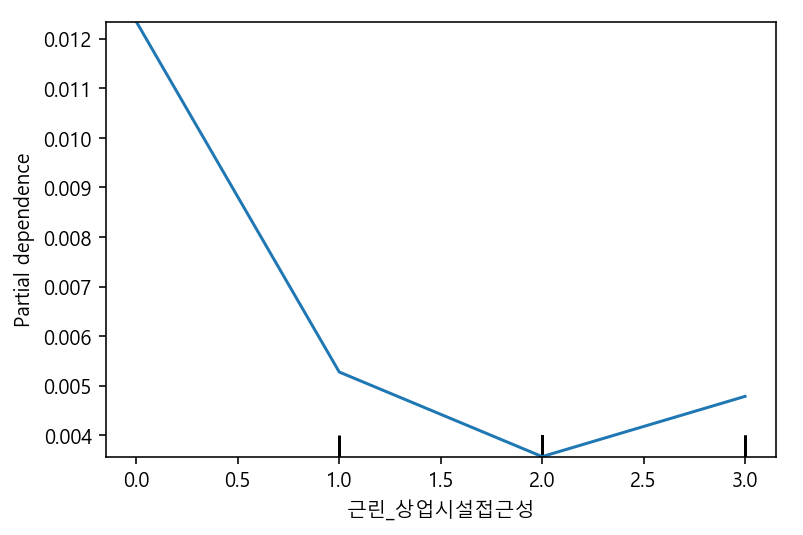

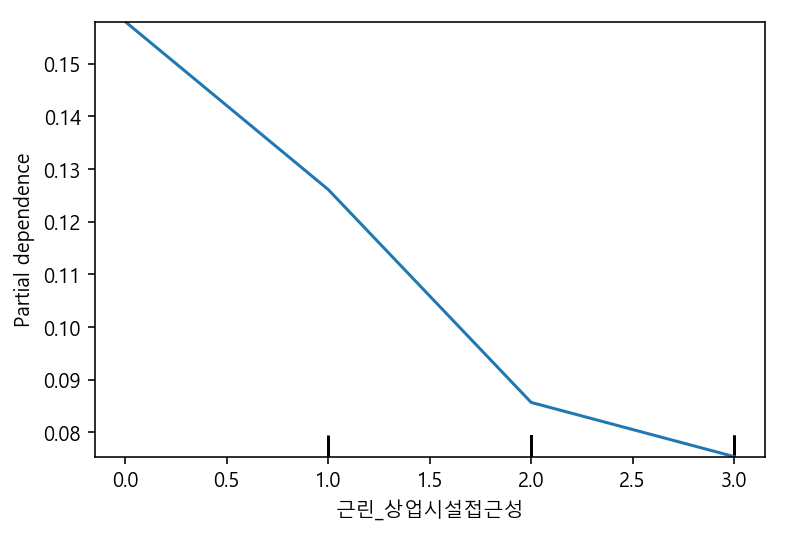

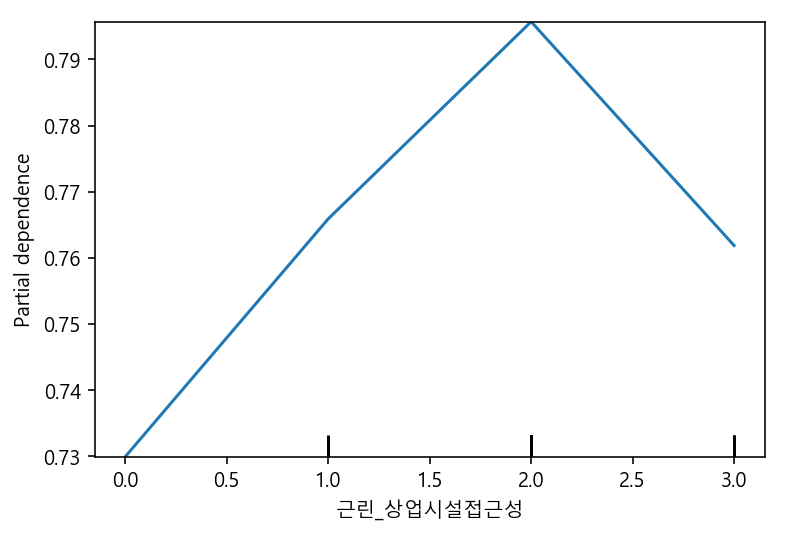

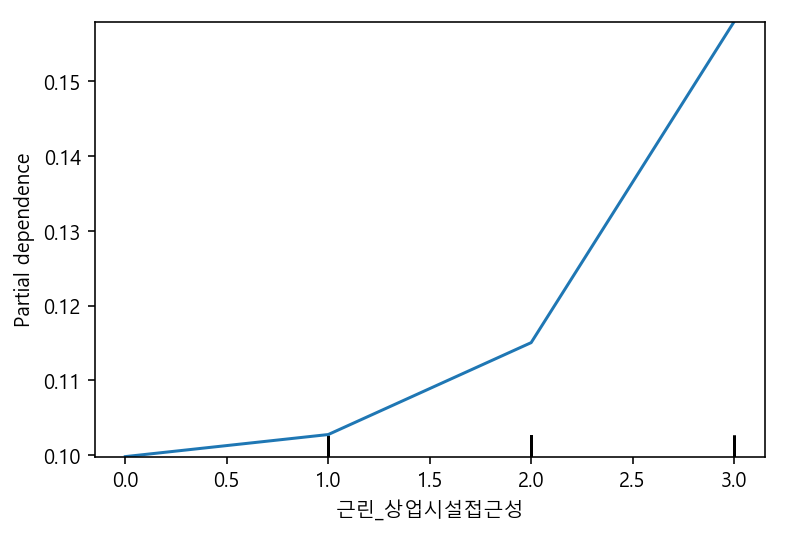

In [39]:
#test
from sklearn.inspection import PartialDependenceDisplay



#features = [0, 1, (0,1)]
#plot_partial_dependence(clf, X_train, features, target=X_test.all())
display_df_0 = PartialDependenceDisplay.from_estimator(
    rfc,
    X_train,
    features=['근린_상업시설접근성'],
    target = 0,
)

display_df_1 = PartialDependenceDisplay.from_estimator(
    rfc,
    X_train,
    features=['근린_상업시설접근성'],
    target = 1,
)

display_df_2 = PartialDependenceDisplay.from_estimator(
    rfc,
    X_train,
    features=['근린_상업시설접근성'],
    target = 2,
)

display_df_3 = PartialDependenceDisplay.from_estimator(
    rfc,
    X_train,
    features=['근린_상업시설접근성'],
    target = 3,
)

In [152]:
import pylab as pl

display_df_0.as_data_frame()

AttributeError: 'AxesSubplot' object has no attribute 'as_data_frame'

In [125]:
type(display_df_0)

matplotlib.axes._subplots.AxesSubplot

TypeError: float() argument must be a string or a number, not 'AxesSubplot'

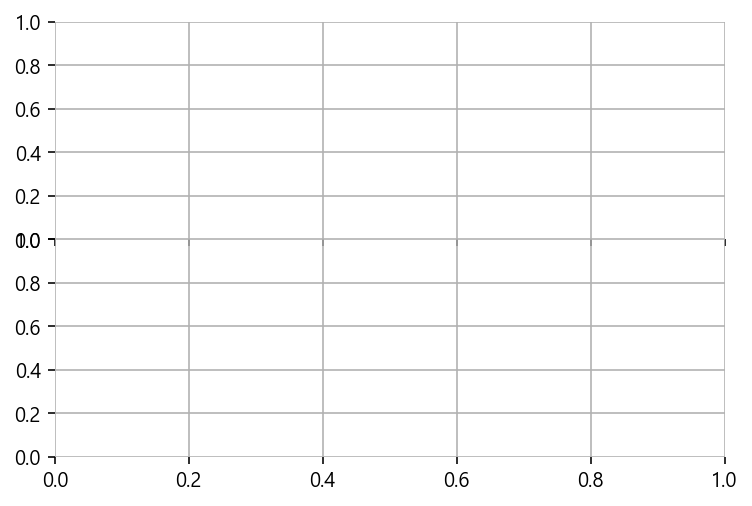

In [138]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(0, 2 * np.pi, 400)
y = np.sin(x ** 2)

fig, (ax1, ax2) = plt.subplots(nrows=2, sharex=True, subplot_kw=dict(frameon=False)) # frameon=False removes frames

plt.subplots_adjust(hspace=.0)
ax1.grid()
ax2.grid()


NameError: name 'plot' is not defined

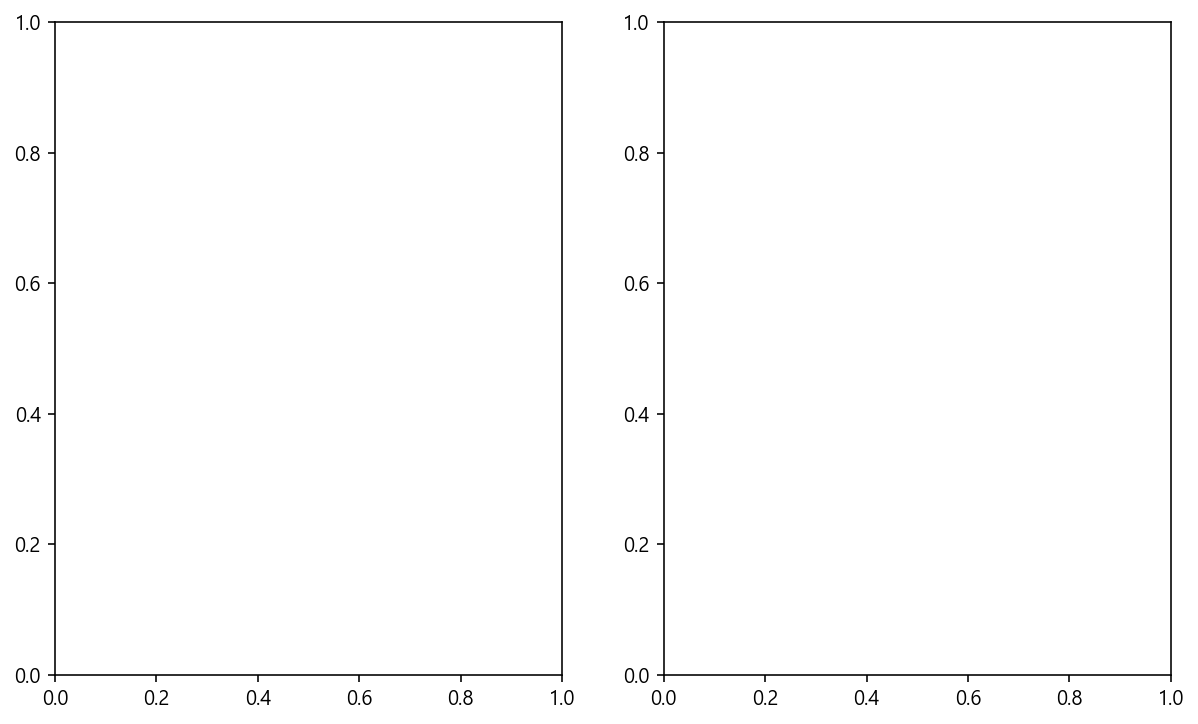

In [118]:
import matplotlib.pyplot as plt

common_params = {
    "subsample": 50,
    "n_jobs": 2,
    "grid_resolution": 20,
    "random_state": 0,
}

print("Computing partial dependence plots...")
display = PartialDependenceDisplay.from_estimator(
    rfc,
    X_train,
    features=["주택_위생"],
    kind="both",
    target=1
)

display.figure_.suptitle(
    "Partial dependence of housing sanitation on housing environment satisfaction\n"
    "for the California housing dataset, with MLPRegressor"
)
display.figure_.subplots_adjust(hspace=0.3)



In [ ]:
from sklearn.inspection import PartialDependenceDisplay

#features = [0, 1, (0,1)]
#plot_partial_dependence(clf, X_train, features, target=X_test.all())
display_df_0 = PartialDependenceDisplay.from_estimator(
    rfc,
    X_train,
    features=['나이', "주택_면적", "근린_의료시설접근성", '근린_교육환경'],
    target = 0,
    n_cols=4
)

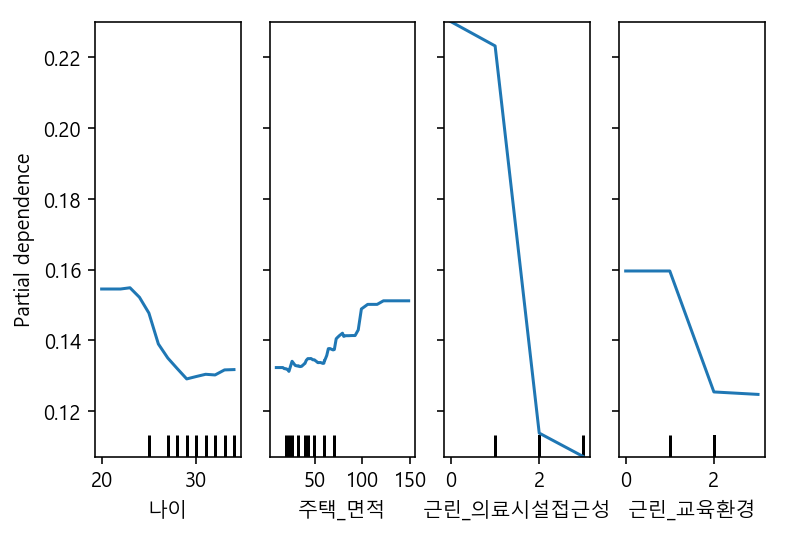

In [83]:
display_df_1 = PartialDependenceDisplay.from_estimator(
    rfc,
    X_train,
    features=['나이', "주택_면적", "근린_의료시설접근성", '근린_교육환경'],
    target = 1,
    n_cols=4
)

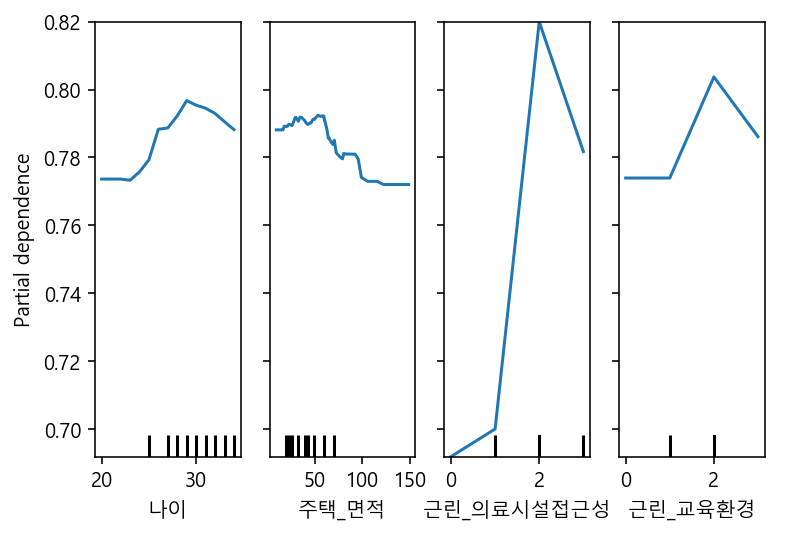

In [84]:
display_df_2 = PartialDependenceDisplay.from_estimator(
    rfc,
    X_train,
    features=['나이', "주택_면적", "근린_의료시설접근성", '근린_교육환경'],
    target = 2,
    n_cols=4
)

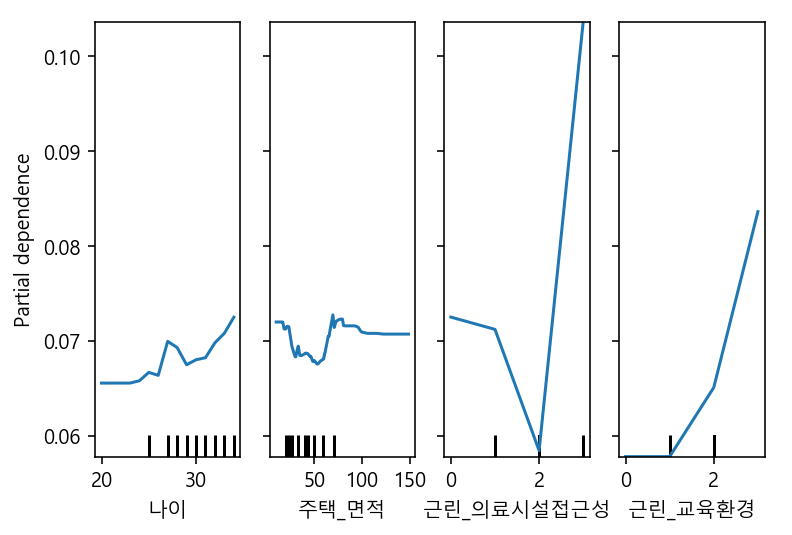

In [85]:
display_df_3 = PartialDependenceDisplay.from_estimator(
    rfc,
    X_train,
    features=['나이', "주택_면적", "근린_의료시설접근성", '근린_교육환경'],
    target = 3,
    n_cols=4
)